# 14 — Baseline: Logistic Regression pada FC Tangent 3 Atlas

**Baseline** adalah model pembanding: model sederhana dan kuat yang dijalankan pada **data, subjek, dan fold yang sama persis** dengan skenario S1–S4. Model usulan dinilai dengan membandingkannya terhadap baseline ini (uji McNemar per subjek di notebook 16–19).

| | |
| :--- | :--- |
| **Masukan** | `data/processed/kohort_dcan.csv` (label, fold) · FC tangent per fold `fitur_dcan_22/tangent_<atlas>_gab_<k>.npy` (notebook 11) |
| **Keluaran** (sudah dibuat oleh notebook 10, **tidak ditimpa** di sini) | `result/tabel/22_cache/C3_gab_tangent_<atlas>.npz`: probabilitas ASD setiap subjek uji, per atlas |
| **Dipakai oleh** | notebook 16–19 sebagai "Baseline LR" (rata-rata probabilitas 3 atlas) |

### Kenapa Logistic Regression?

1. **Paling kuat di bangku uji sebelumnya.** Pada FC tangent berdimensi sangat tinggi (±154 ribu nilai per subjek) dengan ±1.300 subjek latih, model linear berpenalti L2 secara konsisten mengalahkan atau menyamai model yang lebih rumit (SVM, MLP, GNN, 3D CNN).
2. **Mudah dijelaskan.** Setiap konektivitas mendapat satu bobot; prediksi = jumlah berbobot → probabilitas.
3. **Deterministik.** Hasilnya selalu sama setiap dijalankan, sehingga cukup **1 kali run**, berbeda dengan model saraf yang perlu 5 run.

### Cara kerja (sama persis dengan notebook 10)

```
untuk setiap fold uji k (0–4) dan setiap atlas (Gordon, HCP, Markov):
   data latih = 4 fold lain   |   data uji = fold k
   1. standardisasi setiap fitur (rata-rata & SD dari data latih)
   2. pilih kekuatan penalti C dari {1e-5, …, 10} dengan CV 3-fold DI DALAM data latih (skor AUC)
   3. latih ulang LR dengan C terpilih pada seluruh data latih
   4. prediksi probabilitas ASD untuk subjek uji
probabilitas akhir = rata-rata 3 atlas   →   ASD bila ≥ 0,5
```

Data uji **tidak pernah** dipakai untuk memilih C atau menghitung standardisasi.

Lama proses ±2–5 menit: fold 0 dihitung ulang untuk verifikasi, fold lain dibaca dari hasil notebook 10. Ubah `HITUNG_ULANG_SEMUA = True` untuk menghitung ulang kelima fold (±30–60 menit).

## Persiapan

In [1]:
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
from src.metrics import hitung_metrik

# ----- Pengaturan (sama dengan notebook 22) -----
ATLAS = ["gordon2014", "hcp2016", "markov2012"]
GRID_C = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]
INNER = StratifiedKFold(3, shuffle=True, random_state=42)
HITUNG_ULANG_SEMUA = False          # False: hanya fold 0 dihitung ulang (verifikasi); True: kelima fold

FITUR = ROOT / "data" / "processed" / "fitur_dcan_22"
CACHE = ROOT / "result" / "tabel" / "22_cache"
FIG_DIR = ROOT / "result" / "figure"
FIG_DIR.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(ROOT / "data" / "processed" / "kohort_dcan.csv")
y = kohort["label"].to_numpy()
fold = kohort["fold_gabungan"].to_numpy()
dataset = kohort["dataset"].to_numpy()
print(f"Subjek: {len(kohort)} | ASD {y.sum()} | Kontrol {(1 - y).sum()} | fold: {np.bincount(fold).tolist()}")

Subjek: 1638 | ASD 714 | Kontrol 924 | fold: [328, 323, 335, 327, 325]


## 1. Satu Fold secara Rinci (Fold 0)

Untuk fold 0, setiap langkah ditampilkan: berapa subjek latih dan uji, berapa AUC validasi untuk setiap nilai C, C mana yang terpilih, dan probabilitas hasilnya. Probabilitas yang dihitung ulang di sini lalu dicocokkan dengan hasil notebook 10.

**Apa itu C?** C mengatur kekuatan penalti L2. **C kecil = penalti kuat**: bobot dipaksa kecil, sehingga model sederhana dan tidak mudah menghafal data latih. **C besar = penalti lemah**. Nilai C terbaik tidak ditebak, tetapi dipilih otomatis dari AUC validasi. Pada tabel di bawah terlihat bahwa AUC hampir sama untuk C ≥ 0,001; hanya penalti yang terlalu kuat (C = 0,00001) yang jelas lebih buruk. Jadi hasil baseline tidak sensitif terhadap pilihan C yang tepat.

In [2]:
def latih_lr(X, tr, te):
    gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                      {"logisticregression__C": GRID_C}, cv=INNER, scoring="roc_auc", n_jobs=1)
    gs.fit(np.asarray(X[tr]), y[tr])
    return gs, gs.predict_proba(np.asarray(X[te]))[:, 1]

k = 0
tr, te = np.where(fold != k)[0], np.where(fold == k)[0]
print(f"Fold {k}: {len(tr)} subjek latih, {len(te)} subjek uji")
P_ULANG, tabel_c, cek = {}, [], []
for a in ATLAS:
    t0 = time.perf_counter()
    X = np.load(FITUR / f"tangent_{a}_gab_{k}.npy", mmap_mode="r")
    gs, p = latih_lr(X, tr, te)
    P_ULANG[a] = p
    tabel_c.append(pd.Series(gs.cv_results_["mean_test_score"] * 100, index=[f"C={c:g}" for c in GRID_C], name=f"{a} ({X.shape[1]:,} fitur)"))
    simpan = np.load(CACHE / f"C3_gab_tangent_{a}.npz")["p"][te]
    cek.append({"Atlas": a, "C terpilih": gs.best_params_["logisticregression__C"], "AUC validasi terbaik (%)": gs.best_score_ * 100,
                "Selisih probabilitas maks. vs notebook 22": float(np.abs(p - simpan).max()), "Waktu (detik)": time.perf_counter() - t0})
display(pd.DataFrame(tabel_c).round(2).style.set_caption("AUC validasi (CV 3-fold di dalam data latih) untuk setiap nilai C").highlight_max(axis=1))
cek = pd.DataFrame(cek)
cek["Cocok"] = cek["Selisih probabilitas maks. vs notebook 22"] < 1e-6
display(cek.round(4).style.set_caption("C terpilih dan verifikasi terhadap hasil notebook 22"))
assert cek["Cocok"].all(), "hasil LR tidak sama dengan notebook 22"
print("✓ Hasil fold 0 identik dengan notebook 22 (LR deterministik: dijalankan ulang tetap sama).")

Fold 0: 1310 subjek latih, 328 subjek uji


,C=1e-05,C=0.0001,C=0.001,C=0.01,C=0.1,C=1,C=10
"gordon2014 (61,776 fitur)",74.390000,76.410000,76.590000,76.540000,76.490000,76.680000,76.680000
"hcp2016 (71,631 fitur)",75.950000,78.140000,78.480000,78.510000,78.440000,78.390000,78.420000
"markov2012 (20,910 fitur)",72.530000,74.790000,74.940000,74.640000,74.500000,74.250000,74.070000


,Atlas,C terpilih,AUC validasi terbaik (%),Selisih probabilitas maks. vs notebook 22,Waktu (detik),Cocok
0,gordon2014,10.000000,76.684100,0.000000,42.745400,True
1,hcp2016,0.010000,78.507300,0.000000,51.444300,True
2,markov2012,0.001000,74.940100,0.000000,13.849200,True


✓ Hasil fold 0 identik dengan notebook 22 (LR deterministik: dijalankan ulang tetap sama).


## 2. Seluruh Fold

Probabilitas kelima fold diambil dari hasil notebook 10. Kalau `HITUNG_ULANG_SEMUA = True`, kelima fold dihitung ulang dan dicocokkan juga. Prediksi akhir = **rata-rata probabilitas 3 atlas**: setiap atlas membagi otak dengan cara berbeda, sehingga rata-ratanya lebih stabil daripada satu atlas saja.

In [3]:
P_ATLAS = {a: np.load(CACHE / f"C3_gab_tangent_{a}.npz")["p"] for a in ATLAS}
if HITUNG_ULANG_SEMUA:
    for k in range(5):
        tr, te = np.where(fold != k)[0], np.where(fold == k)[0]
        for a in ATLAS:
            _, p = latih_lr(np.load(FITUR / f"tangent_{a}_gab_{k}.npy", mmap_mode="r"), tr, te)
            assert np.abs(p - P_ATLAS[a][te]).max() < 1e-6, f"fold {k} atlas {a} tidak cocok"
        print(f"fold {k}: cocok")
P_LR = np.mean([P_ATLAS[a] for a in ATLAS], axis=0)
assert np.isfinite(P_LR).all()

def ringkas(p):
    df = pd.DataFrame([hitung_metrik(y[fold == f], p[fold == f]) for f in range(5)])
    df["balanced"] = (df["sensitivity"] + df["specificity"]) / 2
    return {f"{n} (%)": f"{df[k].mean() * 100:.2f} ± {df[k].std(ddof=0) * 100:.2f}"
            for k, n in [("accuracy", "Akurasi"), ("balanced", "Balanced acc."), ("sensitivity", "Sensitivitas"),
                         ("specificity", "Spesifisitas"), ("f1", "F1"), ("auc", "AUC")]}

tab = pd.DataFrame({**{f"LR atlas {a} saja": ringkas(P_ATLAS[a]) for a in ATLAS}, "BASELINE LR: rata-rata 3 atlas": ringkas(P_LR)}).T
display(tab.style.set_caption("Baseline LR, rata-rata ± SD antar 5 fold (1.638 subjek)"))
per_fold = pd.DataFrame([{"Fold": f, "Subjek uji": int((fold == f).sum()), **{kk: v * 100 for kk, v in hitung_metrik(y[fold == f], P_LR[fold == f]).items()}}
                         for f in range(5)]).set_index("Fold")
display(per_fold.round(2).style.set_caption("Baseline LR per fold (%)"))

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),F1 (%),AUC (%)
LR atlas gordon2014 saja,71.78 ± 2.18,70.73 ± 2.54,63.11 ± 9.94,78.34 ± 6.59,65.73 ± 4.66,79.72 ± 2.10
LR atlas hcp2016 saja,72.07 ± 2.85,70.37 ± 2.70,57.01 ± 3.78,83.73 ± 3.92,64.02 ± 3.30,80.56 ± 2.01
LR atlas markov2012 saja,70.44 ± 1.64,68.85 ± 1.76,56.33 ± 4.10,81.37 ± 2.30,62.36 ± 2.54,77.83 ± 1.42
BASELINE LR: rata-rata 3 atlas,73.23 ± 3.48,71.83 ± 3.48,61.14 ± 5.65,82.52 ± 3.84,66.50 ± 4.52,81.35 ± 2.14


,Subjek uji,accuracy,sensitivity,specificity,precision,f1,auc
Fold,,,,,,,
0,328,72.260000,65.070000,78.020000,70.370000,67.620000,82.350000
1,323,67.180000,52.080000,79.330000,66.960000,58.590000,77.270000
2,335,77.310000,68.240000,84.490000,77.690000,72.660000,83.420000
3,327,73.700000,62.320000,82.010000,71.670000,66.670000,81.350000
4,325,75.690000,57.970000,88.770000,79.210000,66.950000,82.370000


## 3. Hasil Baseline

- **Kiri**: kurva ROC seluruh subjek uji. AUC di sini dihitung dari **semua subjek sekaligus**, sehingga sedikit berbeda dari AUC di tabel bagian 2 yang merupakan **rata-rata 5 fold**;
- **Tengah**: confusion matrix (ambang 0,5);
- **Kanan**: akurasi per dataset, untuk memeriksa apakah model sama baiknya pada ABIDE I dan ABIDE II.

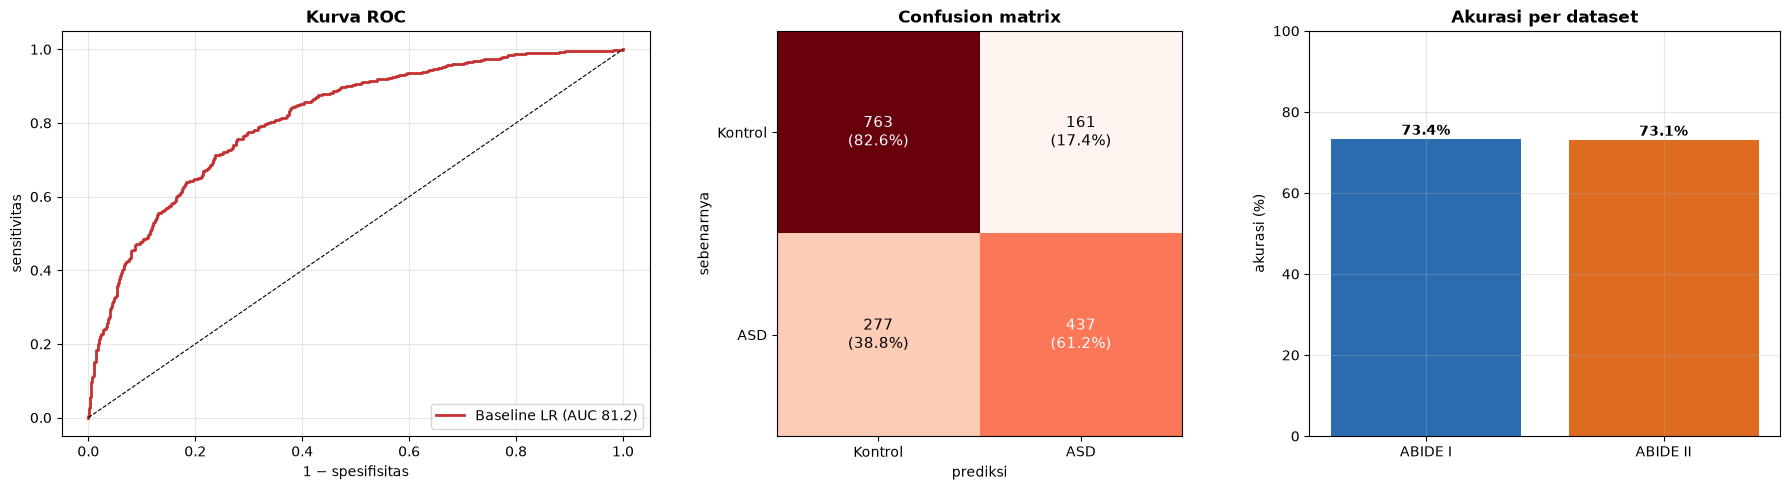

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 0.8, 0.8]})
fpr, tpr, _ = roc_curve(y, P_LR)
axes[0].plot(fpr, tpr, color="#C53030", lw=2, label=f"Baseline LR (AUC {hitung_metrik(y, P_LR)['auc'] * 100:.1f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].legend(loc="lower right")
axes[0].set_xlabel("1 − spesifisitas"); axes[0].set_ylabel("sensitivitas"); axes[0].set_title("Kurva ROC", fontweight="bold")
cm = confusion_matrix(y, (P_LR >= 0.5).astype(int))
axes[1].imshow(cm, cmap="Reds")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}%)", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Kontrol", "ASD"]); axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["Kontrol", "ASD"])
axes[1].set_xlabel("prediksi"); axes[1].set_ylabel("sebenarnya"); axes[1].set_title("Confusion matrix", fontweight="bold")
benar = (P_LR >= 0.5).astype(int) == y
per_ds = pd.Series(benar).groupby(dataset).mean() * 100
axes[2].bar(["ABIDE I", "ABIDE II"], per_ds.values, color=["#2B6CB0", "#DD6B20"])
for i, v in enumerate(per_ds.values):
    axes[2].text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
axes[2].set_ylim(0, 100); axes[2].set_ylabel("akurasi (%)"); axes[2].set_title("Akurasi per dataset", fontweight="bold")
for ax in axes[[0, 2]]:
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "23b_1_hasil_baseline_lr.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Ringkasan

| | |
| :--- | :--- |
| Model | Logistic Regression L2, satu model per atlas, probabilitas dirata-rata 3 atlas |
| Fitur | FC tangent per fold (Gordon 61.776 + HCP 71.631 + Markov 20.910 nilai) |
| Pemilihan C | CV 3-fold **di dalam data latih**, skor AUC |
| Pengulangan | 1 run (deterministik, terbukti identik saat dihitung ulang) |
| Hasil | lihat tabel bagian 2 (akurasi rata-rata 3 atlas ±73%) |

Angka baseline ini yang ditampilkan sebagai **"Baseline LR (notebook 22)"** (label memakai nomor lama; sekarang notebook 10) di notebook skenario 16–19, dan menjadi pembanding uji McNemar model usulan.